# Question 2 - 2D Dense Matrix Multiplication
Basic matrix multiplication program that multiplies a 2D matrix A of (M, N) by matrix B of (N, P) and stores the results into a matrix C (M, P).

In [ ]:
%%writefile matrixMul.cu
#include <stdio.h>
#include <stdlib.h>
#include <sys/time.h>
#include <time.h>

#define BLOCK_SIZE 16

double cpuSecond() {
    struct timeval tp;
    gettimeofday(&tp, NULL);
    return ((double)tp.tv_sec + (double)tp.tv_usec * 1.e-6);
}

// Matrix Multiplication Kernel
__global__ void matrixMulKernel(const double *A, const double *B, double *C, int M, int N, int P) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    if (row < M && col < P) {
        double sum = 0.0;
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * P + col];
        }
        C[row * P + col] = sum;
    }
}

int main() {

    srand((unsigned int)time(NULL));

    // Test matrix dimensions (M, N, P) for timing experiments
    int test_sizes[][3] = {
        {2048, 2048, 2048},
        {4096, 4096, 4096},
        {5120, 5120, 5120},
        {6144, 6144, 6144},
        {7168, 7168, 7168},
        {8192, 8192, 8192},
        {9216, 9216, 9216},
        {10240, 10240, 10240}
    };
    /*int test_sizes[][3] = {
        {1024, 8191, 8197}
    };*/
    int num_tests = sizeof(test_sizes) / sizeof(test_sizes[0]);

    printf("M, N, P, H2D_Time_s, Kernel_Time_s, D2H_Time_s\n");

    for (int t = 0; t < num_tests; t++) {
        int M = test_sizes[t][0];
        int N = test_sizes[t][1];
        int P = test_sizes[t][2];

        size_t size_A = (size_t)M * N * sizeof(double);
        size_t size_B = (size_t)N * P * sizeof(double);
        size_t size_C = (size_t)M * P * sizeof(double);

        double *h_A = (double *)malloc(size_A);
        double *h_B = (double *)malloc(size_B);
        double *h_C = (double *)malloc(size_C);

        // Initialize host inputs with random floating-point values between 0.0 and 1.0
        for (size_t i = 0; i < (size_t)M * N; i++) {
            h_A[i] = (double)rand() / RAND_MAX;
        }
        for (size_t i = 0; i < (size_t)N * P; i++) {
            h_B[i] = (double)rand() / RAND_MAX;
        }

        // GPU Setup
        double *d_A, *d_B, *d_C;
        cudaMalloc((void **)&d_A, size_A);
        cudaMalloc((void **)&d_B, size_B);
        cudaMalloc((void **)&d_C, size_C);

        double start_H2D = cpuSecond();
        cudaMemcpy(d_A, h_A, size_A, cudaMemcpyHostToDevice);
        cudaMemcpy(d_B, h_B, size_B, cudaMemcpyHostToDevice);
        cudaDeviceSynchronize();
        double time_H2D = cpuSecond() - start_H2D;

        dim3 threadsPerBlock(BLOCK_SIZE, BLOCK_SIZE);
        dim3 numBlocks((P + threadsPerBlock.x - 1) / threadsPerBlock.x,
                       (M + threadsPerBlock.y - 1) / threadsPerBlock.y);

        double start_Kernel = cpuSecond();
        matrixMulKernel<<<numBlocks, threadsPerBlock>>>(d_A, d_B, d_C, M, N, P);
        cudaDeviceSynchronize();
        double time_Kernel = cpuSecond() - start_Kernel;

        double start_D2H = cpuSecond();
        cudaMemcpy(h_C, d_C, size_C, cudaMemcpyDeviceToHost);
        cudaDeviceSynchronize();
        double time_D2H = cpuSecond() - start_D2H;

        // Print results for plots
        printf("%d, %d, %d, %f, %f, %f\n", M, N, P, time_H2D, time_Kernel, time_D2H);

        // Cleanup current iteration
        free(h_A); free(h_B); free(h_C);
        cudaFree(d_A); cudaFree(d_B); cudaFree(d_C);
    }

    return 0;
}

Overwriting matrixMul.cu


In [ ]:
!nvcc -O3 matrixMul.cu -o matrixMul

In [ ]:
!./matrixMul

M, N, P, H2D_Time_s, Kernel_Time_s, D2H_Time_s
1024, 8191, 8197, 0.129214, 0.763963, 0.043666


Profiling


In [ ]:
!ncu ./matrixMul

M, N, P, H2D_Time_s, Kernel_Time_s, D2H_Time_s
==PROF== Connected to process 15408 (/content/matrixMul)
==PROF== Profiling "matrixMulKernel" - 0: 0%....50%....100% - 9 passes
1024, 8191, 8197, 0.138794, 15.942717, 0.053976
==PROF== Disconnected from process 15408
[15408] matrixMul@127.0.0.1
  matrixMulKernel(const double *, const double *, double *, int, int, int) (513, 64, 1)x(16, 16, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: GPU Speed Of Light Throughput
    ----------------------- ----------- --------------
    Metric Name             Metric Unit   Metric Value
    ----------------------- ----------- --------------
    DRAM Frequency                  Ghz           5.00
    SM Frequency                    Mhz         585.00
    Elapsed Cycles                cycle    892,132,503
    Memory Throughput                 %          25.86
    DRAM Throughput                   %          12.60
    Duration                          s           1.53
    L1/TEX Cache Throughput    

Plot

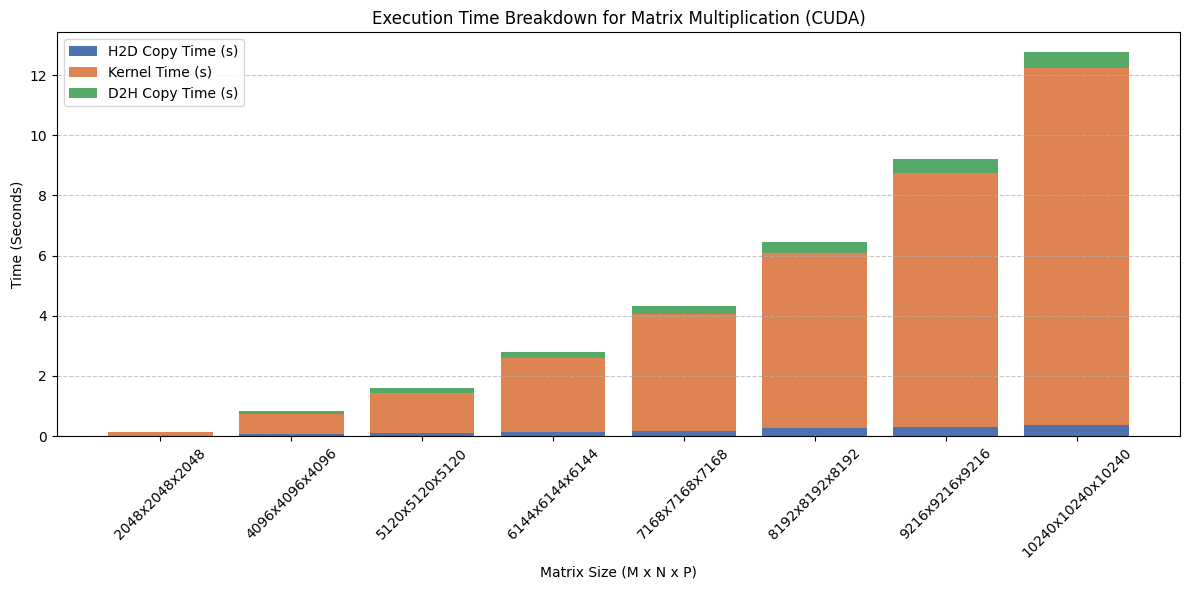

In [ ]:
import subprocess
import pandas as pd
import matplotlib.pyplot as plt
import io

# Run executable and capture CSV output
result = subprocess.run(['./matrixMul'], capture_output=True, text=True)
output_lines = [line for line in result.stdout.split('\n') if ',' in line]
csv_data = "\n".join(output_lines)

# Parse CSV into a Pandas DataFrame
df = pd.read_csv(io.StringIO(csv_data))
df.columns = df.columns.str.strip()

# Create label for plotting
df['Label'] = df.apply(lambda row: f"{int(row['M'])}x{int(row['N'])}x{int(row['P'])}", axis=1)

# Plot Stacked Bar Chart
plt.figure(figsize=(12, 6))

bar1 = plt.bar(df['Label'], df['H2D_Time_s'], label='H2D Copy Time (s)', color='#4C72B0')
bar2 = plt.bar(df['Label'], df['Kernel_Time_s'], bottom=df['H2D_Time_s'], label='Kernel Time (s)', color='#DD8452')
bar3 = plt.bar(df['Label'], df['D2H_Time_s'], bottom=df['H2D_Time_s'] + df['Kernel_Time_s'], label='D2H Copy Time (s)', color='#55A868')

plt.xlabel('Matrix Size (M x N x P)')
plt.ylabel('Time (Seconds)')
plt.title('Execution Time Breakdown for Matrix Multiplication (CUDA)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('stacked_bar_chart.png', dpi=300)
plt.show()

## FLOAT

In [ ]:
%%writefile matrixMul.cu
#include <stdio.h>
#include <stdlib.h>
#include <sys/time.h>
#include <time.h>

#define BLOCK_SIZE 16

double cpuSecond() {
    struct timeval tp;
    gettimeofday(&tp, NULL);
    return ((double)tp.tv_sec + (double)tp.tv_usec * 1.e-6);
}

// Matrix Multiplication Kernel
__global__ void matrixMulKernel(const float *A, const float *B, float *C, int M, int N, int P) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    if (row < M && col < P) {
        float sum = 0.0f;
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * P + col];
        }
        C[row * P + col] = sum;
    }
}

int main() {

    srand((unsigned int)time(NULL));

    int test_sizes[][3] = {
        {2048, 2048, 2048},
        {4096, 4096, 4096},
        {5120, 5120, 5120},
        {6144, 6144, 6144},
        {7168, 7168, 7168},
        {8192, 8192, 8192},
        {9216, 9216, 9216},
        {10240, 10240, 10240}
    };
    int num_tests = sizeof(test_sizes) / sizeof(test_sizes[0]);

    printf("M,N,P,H2D_Time_s,Kernel_Time_s,D2H_Time_s\n");

    for (int t = 0; t < num_tests; t++) {
        int M = test_sizes[t][0];
        int N = test_sizes[t][1];
        int P = test_sizes[t][2];

        size_t size_A = (size_t)M * N * sizeof(float);
        size_t size_B = (size_t)N * P * sizeof(float);
        size_t size_C = (size_t)M * P * sizeof(float);

        float *h_A = (float *)malloc(size_A);
        float *h_B = (float *)malloc(size_B);
        float *h_C = (float *)malloc(size_C);

        for (size_t i = 0; i < (size_t)M * N; i++) {
            h_A[i] = (float)rand() / RAND_MAX;
        }
        for (size_t i = 0; i < (size_t)N * P; i++) {
            h_B[i] = (float)rand() / RAND_MAX;
        }

        float *d_A, *d_B, *d_C;
        cudaMalloc((void **)&d_A, size_A);
        cudaMalloc((void **)&d_B, size_B);
        cudaMalloc((void **)&d_C, size_C);

        double start_H2D = cpuSecond();
        cudaMemcpy(d_A, h_A, size_A, cudaMemcpyHostToDevice);
        cudaMemcpy(d_B, h_B, size_B, cudaMemcpyHostToDevice);
        cudaDeviceSynchronize();
        double time_H2D = cpuSecond() - start_H2D;

        dim3 threadsPerBlock(BLOCK_SIZE, BLOCK_SIZE);
        dim3 numBlocks((P + threadsPerBlock.x - 1) / threadsPerBlock.x,
                       (M + threadsPerBlock.y - 1) / threadsPerBlock.y);

        double start_Kernel = cpuSecond();
        matrixMulKernel<<<numBlocks, threadsPerBlock>>>(d_A, d_B, d_C, M, N, P);
        cudaDeviceSynchronize();
        double time_Kernel = cpuSecond() - start_Kernel;

        double start_D2H = cpuSecond();
        cudaMemcpy(h_C, d_C, size_C, cudaMemcpyDeviceToHost);
        cudaDeviceSynchronize();
        double time_D2H = cpuSecond() - start_D2H;

        printf("%d,%d,%d,%f,%f,%f\n", M, N, P, time_H2D, time_Kernel, time_D2H);

        free(h_A); free(h_B); free(h_C);
        cudaFree(d_A); cudaFree(d_B); cudaFree(d_C);
    }

    return 0;
}

Overwriting matrixMul.cu


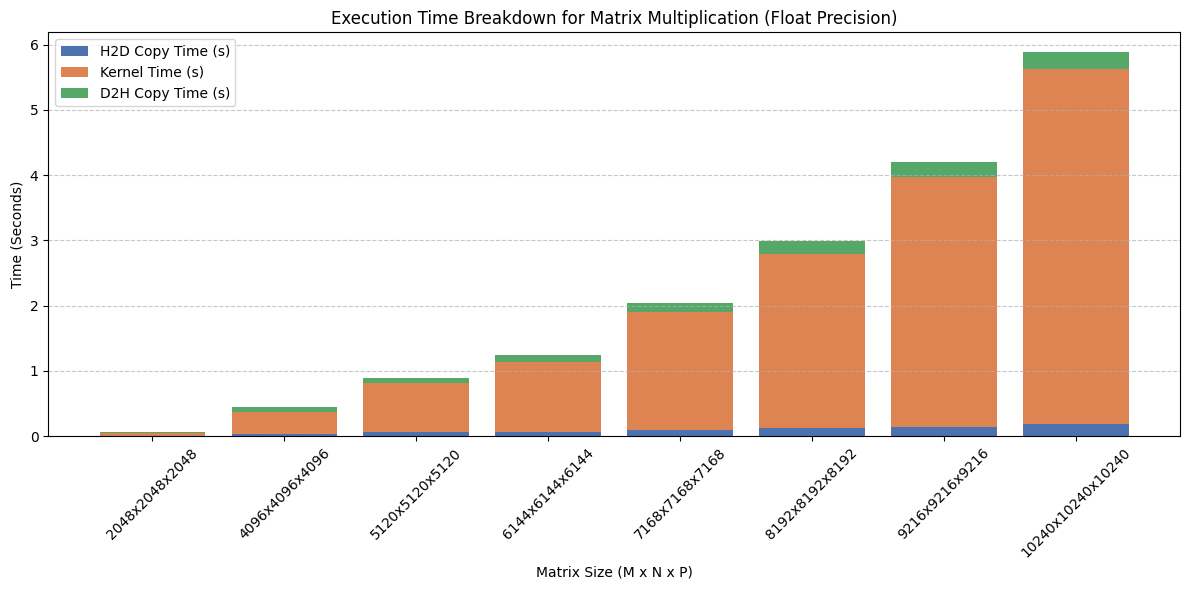

In [ ]:
import subprocess
import pandas as pd
import matplotlib.pyplot as plt
import io

# Run executable and capture CSV output
result = subprocess.run(['./matrixMul'], capture_output=True, text=True)
output_lines = [line for line in result.stdout.split('\n') if ',' in line]
csv_data = "\n".join(output_lines)

# Parse CSV
df = pd.read_csv(io.StringIO(csv_data))
df.columns = df.columns.str.strip()

# Create label for plotting
df['Label'] = df.apply(lambda row: f"{int(row['M'])}x{int(row['N'])}x{int(row['P'])}", axis=1)

# Plot Stacked Bar Chart
plt.figure(figsize=(12, 6))

bar1 = plt.bar(df['Label'], df['H2D_Time_s'], label='H2D Copy Time (s)', color='#4C72B0')
bar2 = plt.bar(df['Label'], df['Kernel_Time_s'], bottom=df['H2D_Time_s'], label='Kernel Time (s)', color='#DD8452')
bar3 = plt.bar(df['Label'], df['D2H_Time_s'], bottom=df['H2D_Time_s'] + df['Kernel_Time_s'], label='D2H Copy Time (s)', color='#55A868')

plt.xlabel('Matrix Size (M x N x P)')
plt.ylabel('Time (Seconds)')
plt.title('Execution Time Breakdown for Matrix Multiplication (Float Precision)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('stacked_bar_chart_float.png', dpi=300)
plt.show()